# Inicio

Librerías

In [256]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
sb.set_style("whitegrid")

Data

In [257]:
data = pd.read_csv("data/urbania_inmuebles.csv", low_memory=False)
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1922 entries, 0 to 1921
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                1922 non-null   int64  
 1   region            1922 non-null   str    
 2   ciudad            1922 non-null   str    
 3   distrito          499 non-null    str    
 4   area_m2           1919 non-null   float64
 5   dormitorios       1850 non-null   float64
 6   banos             1854 non-null   float64
 7   precio            1922 non-null   int64  
 8   moneda            1922 non-null   str    
 9   precio_pen        1922 non-null   int64  
 10  precio_usd        1543 non-null   float64
 11  tipo_inmueble     1922 non-null   str    
 12  tipo_aviso        1922 non-null   str    
 13  etapa             1922 non-null   str    
 14  tipo_conjunto     1922 non-null   str    
 15  areas_comunes     1922 non-null   str    
 16  amenidades        1174 non-null   str    
 17  estaci

# Ajustes

In [258]:
df = data.copy()

Nulos

In [259]:
for col in df.columns:
    nuls = len(df[df[col].isna()])
    if nuls > 0:
        print(col, nuls)

distrito 1423
area_m2 3
dormitorios 72
banos 68
precio_usd 379
amenidades 748
estacionamientos 1150
mantenimiento 1545


In [260]:
# Tratamiento de nulos
df["estacionamientos"] = df["estacionamientos"].fillna(0)
df["distrito"] = df["distrito"].fillna("-")

Filtro general para eliminar outliers

In [261]:
# Filtros
print(f"Registros antes de filtros: {len(df)}")
df = df[
    (df["precio_pen"]>df["precio_pen"].quantile(0.05)) &
    (df["precio_pen"]<df["precio_pen"].quantile(0.95)) &
    (df["area_m2"]>=30) &
    (df["area_m2"]<=500) &
    (df["dormitorios"]<=7) &
    (df["banos"]<=7) &
    (df["estacionamientos"]<=4)
]
print(f"Registros luego de filtros: {len(df)}")

Registros antes de filtros: 1922
Registros luego de filtros: 1411


Variables nuevas

In [262]:
# Precios a float
df[["precio", "precio_pen", "precio_usd"]] = df[["precio", "precio_pen", "precio_usd"]].astype(float)

# Tipo de cambio único para los avisos en USD
TC = 3.40
es_usd = df["moneda"] == "USD"
df.loc[es_usd, "precio_pen"] = df.loc[es_usd, "precio"] * TC

# Precio en miles de soles
df["precio_pen_k"] = df["precio_pen"] / 1_000

# Precio por m2
df["precio_pen_m2"] = df["precio_pen"] / df["area_m2"]

# Precio por m2 con respecto a la mediana del segmento
seg = ["region", "ciudad", "distrito", "tipo_inmueble"]
df["m2_mediana_seg"] = df.groupby(seg, dropna=False)["precio_pen_m2"].transform("median")
df["indice_m2"] = df["precio_pen_m2"] / df["m2_mediana_seg"]

# Nueva región (regiones con menos de 15 registros son "Otra")
r = df["region"].value_counts(dropna=False)
other = r[r<15].index.to_list()
df.loc[df["region"].isin(other), "region"] = "Otra"

# Igual para ciudad y distrito, pero 10
r = df["ciudad"].value_counts(dropna=False)
other = r[r<10].index.to_list()
df.loc[df["ciudad"].isin(other), "ciudad"] = "Otra"
r = df["distrito"].value_counts(dropna=False)
other = r[r<10].index.to_list()
df.loc[df["distrito"].isin(other), "distrito"] = "Otra"

# Dormitorio, baño y estacionamiento a int
df[["dormitorios", "banos", "estacionamientos"]] = df[["dormitorios", "banos", "estacionamientos"]].astype(int)

# Revisión (EDA)

Columnas del DF

In [263]:
df.columns

Index(['id', 'region', 'ciudad', 'distrito', 'area_m2', 'dormitorios', 'banos',
       'precio', 'moneda', 'precio_pen', 'precio_usd', 'tipo_inmueble',
       'tipo_aviso', 'etapa', 'tipo_conjunto', 'areas_comunes', 'amenidades',
       'estacionamientos', 'mantenimiento', 'ubicacion', 'url',
       'fecha_scraping', 'precio_pen_k', 'precio_pen_m2', 'm2_mediana_seg',
       'indice_m2'],
      dtype='str')

### Variables continuas

In [264]:
CONT_VARIABLES = [
    'precio_pen',
    'area_m2',
]

In [265]:
df[CONT_VARIABLES].describe().round(2)

,precio_pen,area_m2
count,1411.00,1411.00
mean,688373.23,150.66
std,494725.37,95.39
min,187000.00,31.00
25%,351750.00,80.00
50%,527000.00,120.00
75%,850000.00,199.50
max,3281000.00,500.00


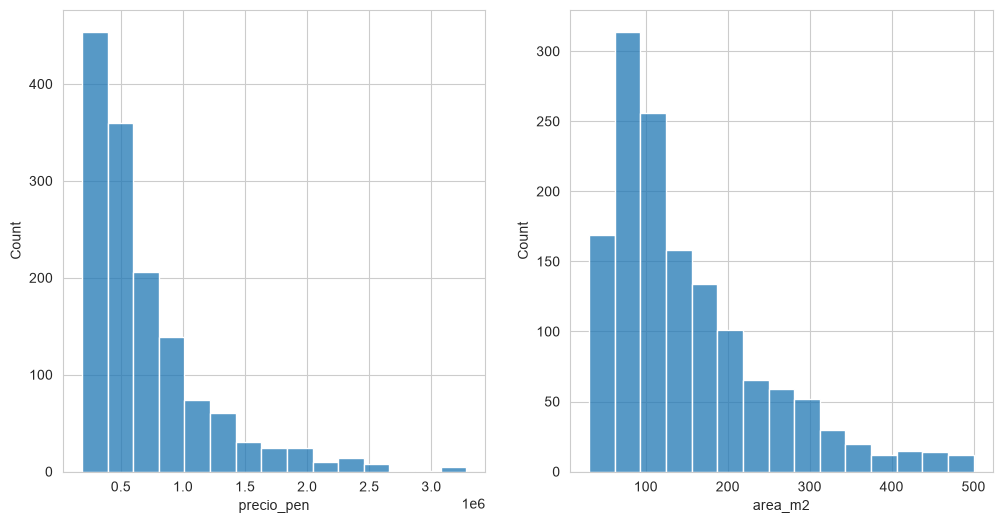

In [266]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(12,6))

for i, feat in enumerate(CONT_VARIABLES):
    sb.histplot(data=df, x=feat, bins=15, ax=axs[i])
plt.show()

### Variables categóricas

In [267]:
CATE_VARIABLES = [
    'region', 'ciudad', 'distrito',
    'dormitorios', 'banos', 'estacionamientos',
    'tipo_inmueble', 'tipo_aviso', 'etapa', 'tipo_conjunto', 'areas_comunes'
]

In [268]:
for col in CATE_VARIABLES:
    print(df[col].value_counts(dropna=False), "\n")

region
Lima           590
Arequipa       180
Callao         159
Lambayeque     139
La Libertad     90
Piura           71
Ica             65
Cusco           52
Otra            50
Junín           15
Name: count, dtype: int64 

ciudad
Lima        424
Callao      159
Arequipa    154
Cañete      148
Chiclayo    135
Otra         96
Trujillo     86
Piura        57
Cusco        45
Ica          33
Islay        18
Pisco        18
Huancayo     15
Chincha      13
Maynas       10
Name: count, dtype: int64 

distrito
-                    987
Miraflores            77
San Isidro            58
Santiago de Surco     57
Otra                  34
Surquillo             32
San Miguel            25
Chorrillos            25
Magdalena del Mar     23
Pueblo Libre          15
Lima                  14
San Borja             14
La Victoria           13
Jesús María           13
La Molina             12
Lince                 12
Name: count, dtype: int64 

dormitorios
3    586
4    258
2    249
5    127
1     83
6     

### Distribución de precios

Precio por región

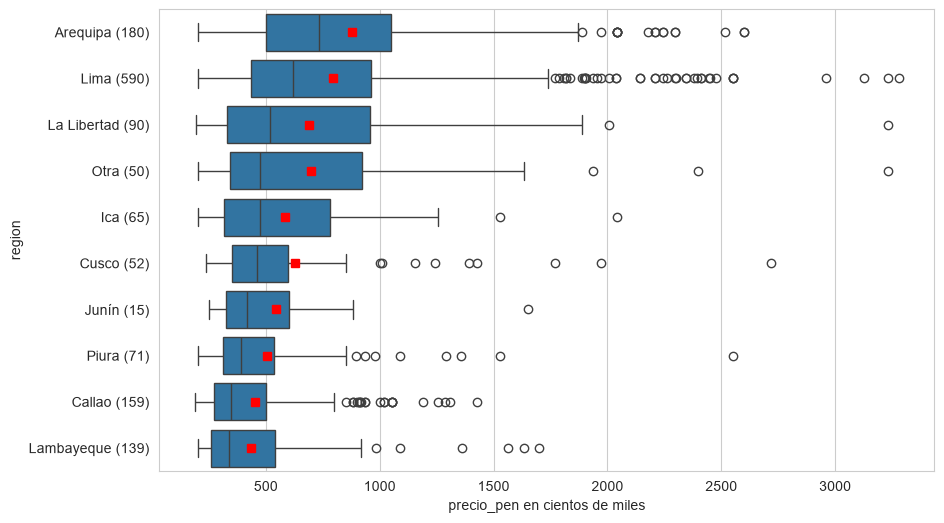

In [269]:
orden = df.groupby("region")["precio_pen"].median().sort_values(ascending=False).index
n = df.groupby("region")["precio_pen"].count()

fig, ax = plt.subplots(figsize=(10,6))
sb.boxplot(data=df, x="precio_pen_k", y="region", ax=ax, order=orden, orient="h",
           showmeans=True,
           meanprops={"marker": "s", "markerfacecolor": "red", "markeredgecolor": "red", "markersize": 6},
           )
ax.set_yticks(range(len(orden)))
ax.set_yticklabels([f"{r} ({n[r]})" for r in orden])
ax.set_xlabel("precio_pen en cientos de miles")
plt.show()

Precio por m2 por región

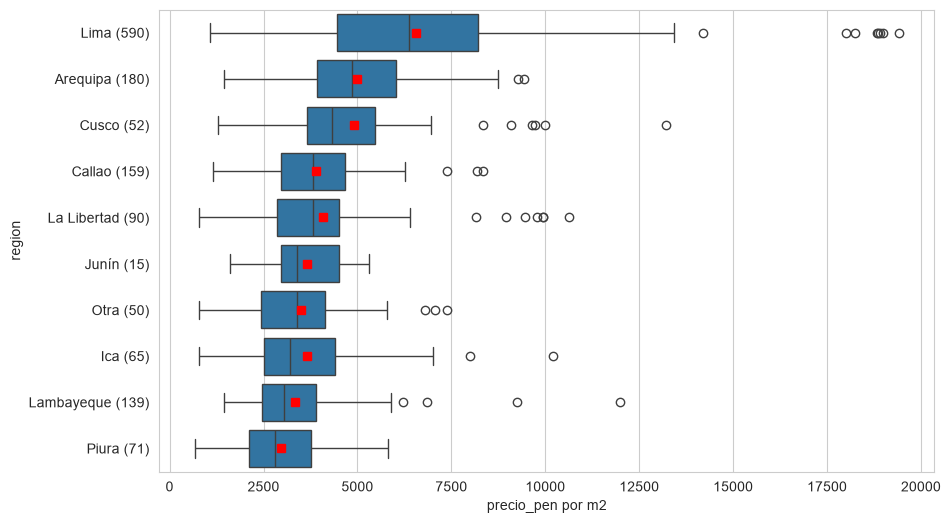

In [270]:
orden = df.groupby("region")["precio_pen_m2"].median().sort_values(ascending=False).index
n = df.groupby("region")["precio_pen_m2"].count()

fig, ax = plt.subplots(figsize=(10,6))
sb.boxplot(data=df, x="precio_pen_m2", y="region", ax=ax, order=orden, orient="h",
           showmeans=True,
           meanprops={"marker": "s", "markerfacecolor": "red", "markeredgecolor": "red", "markersize": 6})
ax.set_yticks(range(len(orden)))
ax.set_yticklabels([f"{r} ({n[r]})" for r in orden])
ax.set_xlabel("precio_pen por m2")
plt.show()

In [271]:
df["indice_m2"].describe()

count    1411.000000
mean        1.047810
std         0.363570
min         0.201746
25%         0.856583
50%         1.000000
75%         1.169557
max         3.616604
Name: indice_m2, dtype: float64

In [272]:
df[
    (df["region"]=="Lima") & (df["ciudad"]=="Lima") &
    (df["precio_pen"]<400_000) &
    (df["area_m2"]>70) &
    (df["indice_m2"]<0.7) &
    (df["dormitorios"]>=2)
].sort_values("indice_m2", ascending=False)

,id,region,ciudad,distrito,area_m2,dormitorios,banos,precio,moneda,precio_pen,...,amenidades,estacionamientos,mantenimiento,ubicacion,url,fecha_scraping,precio_pen_k,precio_pen_m2,m2_mediana_seg,indice_m2
6,148807303,Lima,Lima,Surquillo,80.0,2,1,115000.0,USD,391000.0,...,NaN,0,NaN,"Surquillo, Lima",https://urbania.pe/inmueble/clasificado/veclap...,2026-10-23,391.0,4887.500000,7512.775,0.650559
3,151327256,Lima,Lima,Pueblo Libre,104.0,2,1,105000.0,USD,357000.0,...,NaN,1,NaN,"Pueblo Libre, Lima",https://urbania.pe/inmueble/clasificado/veclap...,2026-10-23,357.0,3432.692308,6185.640,0.554945
425,149734931,Lima,Lima,Pueblo Libre,180.0,2,1,115000.0,USD,391000.0,...,gimnasio,0,NaN,"Pueblo Libre, Lima",https://urbania.pe/inmueble/clasificado/veclap...,2026-10-23,391.0,2172.222222,6185.640,0.351172


In [273]:
df.loc[6, "url"]

'https://urbania.pe/inmueble/clasificado/veclapin-venta-de-departamento-en-surquillo-lima-2-dormitorios-148807303'

# Features

Variables

In [274]:
NOMINAL_CATE_FEATURES = [
    'region', 'ciudad', 'distrito',
    'tipo_inmueble', 'tipo_aviso', 'tipo_conjunto',
    'areas_comunes'
]

ORDINAL_CATE_FEATURES = [
    'etapa'
]

CATE_FEATURES = NOMINAL_CATE_FEATURES + ORDINAL_CATE_FEATURES

CONT_FEATURES = [
    'area_m2', 'dormitorios', 'banos', 'estacionamientos'
]

ALL_FEATURES = CATE_FEATURES + CONT_FEATURES

# Prueba

Matrices X e y

In [275]:
X = df[CATE_FEATURES + CONT_FEATURES]
y = df["precio_pen"]

Split

In [276]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=X["region"])
X_train = X_train.copy()
X_test = X_test.copy()

Preprocesamiento

In [277]:
from sklearn.preprocessing import OrdinalEncoder

ordi_enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)

X_train[CATE_FEATURES] = ordi_enc.fit_transform(X_train[CATE_FEATURES])
X_test[CATE_FEATURES] = ordi_enc.transform(X_test[CATE_FEATURES])

Modelo RF optimizado

In [280]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint, uniform

region_train = df.loc[X_train.index, "region"]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_splits = list(skf.split(X_train, region_train))

param_dist = {
    "n_estimators": randint(200, 800),
    "max_depth": [None, 6, 10, 15, 20, 30],
    "min_samples_split": randint(2, 20),
    "min_samples_leaf": randint(1, 10),
    "max_features": ["sqrt", "log2", 0.3, 0.5, 0.7, 1.0],
    "max_samples": uniform(0.5, 0.5),
}

search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=100,
    cv=cv_splits,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
    verbose=1,
)
search.fit(X_train, y_train)

print("Mejores hiperparámetros:", search.best_params_)
print("RMSE CV (PEN):", round(-search.best_score_, 2))

model = search.best_estimator_

Fitting 5 folds for each of 100 candidates, totalling 500 fits
Mejores hiperparámetros: {'max_depth': 10, 'max_features': 0.7, 'max_samples': np.float64(0.9702659135676917), 'min_samples_leaf': 3, 'min_samples_split': 6, 'n_estimators': 649}
RMSE CV (PEN): 283762.28


Métricas

         R2       RMSE        MAE     MedAE  MAPE %
train  0.84  196722.83  122478.23  68641.96   19.64
test   0.68  287721.49  170779.71  95035.39   26.59


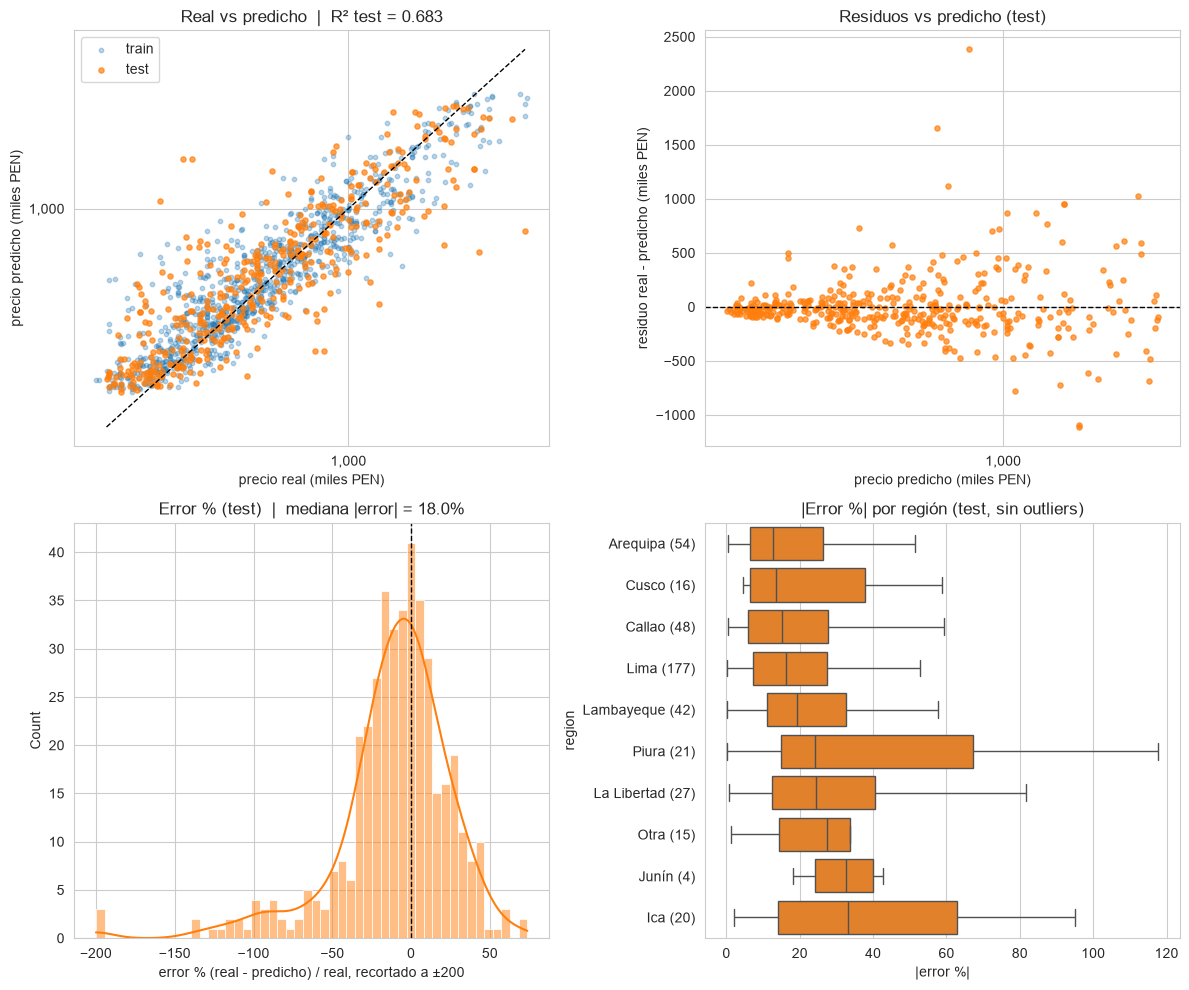

In [281]:
from matplotlib.ticker import FuncFormatter, NullFormatter
from sklearn.metrics import (r2_score, mean_absolute_error, root_mean_squared_error,
                             mean_absolute_percentage_error, median_absolute_error)

pred_train = model.predict(X_train)
pred_test = model.predict(X_test)

# Tabla de métricas
metricas = pd.DataFrame({
    nombre: {
        "R2": r2_score(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "MedAE": median_absolute_error(y_true, y_pred),
        "MAPE %": mean_absolute_percentage_error(y_true, y_pred) * 100,
    }
    for nombre, y_true, y_pred in [("train", y_train, pred_train), ("test", y_test, pred_test)]
}).T
print(metricas.round(2))

# Datos de test para los plots
res = pd.DataFrame({
    "real": y_test,
    "pred": pred_test,
    "region": df.loc[X_test.index, "region"],
})
res["residuo"] = res["real"] - res["pred"]
res["error_pct"] = res["residuo"] / res["real"] * 100
res["abs_pct"] = res["error_pct"].abs()

miles = FuncFormatter(lambda v, _: f"{v:,.0f}")
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

# 1. Real vs predicho (log-log)
ax = axs[0, 0]
ax.scatter(y_train / 1_000, pred_train / 1_000, s=10, alpha=0.3, label="train")
ax.scatter(res["real"] / 1_000, res["pred"] / 1_000, s=14, alpha=0.7, label="test")
lim = [res[["real", "pred"]].min().min() / 1_000, res[["real", "pred"]].max().max() / 1_000]
ax.plot(lim, lim, "k--", lw=1)
ax.set_xscale("log")
ax.set_yscale("log")
for eje in (ax.xaxis, ax.yaxis):
    eje.set_major_formatter(miles)
    eje.set_minor_formatter(NullFormatter())
ax.set_xlabel("precio real (miles PEN)")
ax.set_ylabel("precio predicho (miles PEN)")
ax.set_title(f"Real vs predicho  |  R² test = {metricas.loc['test', 'R2']:.3f}")
ax.legend()

# 2. Residuos vs predicho
ax = axs[0, 1]
ax.scatter(res["pred"] / 1_000, res["residuo"] / 1_000, s=14, alpha=0.7, color="C1")
ax.axhline(0, color="k", ls="--", lw=1)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(miles)
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel("precio predicho (miles PEN)")
ax.set_ylabel("residuo real - predicho (miles PEN)")
ax.set_title("Residuos vs predicho (test)")

# 3. Distribución del error porcentual
ax = axs[1, 0]
sb.histplot(res["error_pct"].clip(-200, 200), bins=50, kde=True, ax=ax, color="C1")
ax.axvline(0, color="k", ls="--", lw=1)
ax.set_xlabel("error % (real - predicho) / real, recortado a ±200")
ax.set_title(f"Error % (test)  |  mediana |error| = {res['abs_pct'].median():.1f}%")

# 4. Error porcentual absoluto por región
ax = axs[1, 1]
orden_err = res.groupby("region")["abs_pct"].median().sort_values().index
n_test = res["region"].value_counts()
sb.boxplot(data=res, x="abs_pct", y="region", order=orden_err, orient="h",
           ax=ax, showfliers=False, color="C1")
ax.set_yticks(range(len(orden_err)))
ax.set_yticklabels([f"{r} ({n_test[r]})" for r in orden_err])
ax.set_xlabel("|error %|")
ax.set_title("|Error %| por región (test, sin outliers)")

plt.tight_layout()
plt.show()

# Exportación

Pipeline

In [283]:
import numpy as np
import joblib
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Pipeline completo: encoder + RF con los mejores hiperparámetros
def build_pipeline():
    pre = ColumnTransformer(
        [("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATE_FEATURES),
         ("num", "passthrough", CONT_FEATURES)],
        verbose_feature_names_out=False,
    )
    rf = RandomForestRegressor(random_state=42, n_jobs=-1, **search.best_params_)
    return Pipeline([("pre", pre), ("model", rf)])

# 1. Validación: entrenado sobre train crudo debe reproducir el modelo del notebook
X_train_raw = df.loc[X_train.index, ALL_FEATURES]
X_test_raw = df.loc[X_test.index, ALL_FEATURES]
pipe = build_pipeline().fit(X_train_raw, y_train)
print("Pipeline == modelo notebook:", np.allclose(pipe.predict(X_test_raw), pred_test))

# 2. Modelo final: reentrenar con toda la data
pipe_final = build_pipeline().fit(df[ALL_FEATURES], df["precio_pen"])

# Categorías válidas (lo que no esté aquí se convierte en "Otra")
categorias = {c: sorted(df[c].unique().tolist()) for c in ["region", "ciudad", "distrito"]}

joblib.dump({
    "pipeline": pipe_final,
    "features": ALL_FEATURES,
    "categorias": categorias,
    "sklearn_version": sklearn.__version__,
    "metricas_test": metricas.loc["test"].to_dict(),
}, "modelo_precio_inmuebles.pkl", compress=3)

Pipeline == modelo notebook: True


['modelo_precio_inmuebles.pkl']